<a href="https://colab.research.google.com/github/ferresmanuela/credit-default-ml/blob/main/proyecto_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción de Default en Tarjetas de Crédito
**Autor:** Pablo Ferres — Data Science II: Machine Learning (Coderhouse)

## 1. Formulación del problema

**Contexto de negocio:** Una entidad emisora de tarjetas de crédito necesita anticipar qué clientes no pagarán su resumen el mes siguiente, para tomar acciones preventivas (reducción de límite, contacto de cobranza, refinanciación).

**Tarea:** Clasificación binaria supervisada.

**Variable objetivo:** `default` → 1 = el cliente incurre en default el mes siguiente; 0 = paga.

**Métricas de éxito:**
- **ROC AUC** (métrica principal): mide la capacidad del modelo de ordenar clientes por riesgo, independientemente del umbral.
- **Recall de la clase 1** (métrica de negocio): un falso negativo (no detectar a un moroso) tiene un costo mucho mayor que un falso positivo (revisar a un buen pagador).

**Dataset:** *Default of Credit Card Clients* (UCI Machine Learning Repository, id 350). 30.000 clientes de Taiwán, abril–septiembre 2005.

**Hipótesis:**
1. El historial reciente de atrasos (`PAY_0`) es el predictor más fuerte de default.
2. Los clientes con alta utilización del límite (deuda / límite) tienen mayor probabilidad de default.
3. Los clientes que pagan una proporción baja de lo facturado presentan mayor riesgo.
4. Las variables demográficas (sexo, estado civil, educación) tienen menor poder predictivo que las de comportamiento de pago.


In [ ]:
!pip install ucimlrepo xgboost shap -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from ucimlrepo import fetch_ucirepo

# Semilla fija para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 30)
plt.style.use('seaborn-v0_8-whitegrid')

## 2. Carga de datos
Se descargan los datos directamente desde el repositorio de UCI con `ucimlrepo`, lo que garantiza que cualquier persona pueda reproducir el notebook sin descargar archivos manualmente.

In [ ]:
credit = fetch_ucirepo(id=350)
X_raw = credit.data.features.copy()
y_raw = credit.data.targets.copy()

print("Columnas originales:", X_raw.columns.tolist()[:5], "...")
print("Shape X:", X_raw.shape, "| Shape y:", y_raw.shape)

Columnas originales: ['X1', 'X2', 'X3', 'X4', 'X5'] ...
Shape X: (30000, 23) | Shape y: (30000, 1)


In [ ]:
# Nombres según la documentación oficial de UCI
cols = ['LIMIT_BAL','SEX','EDUCATION','MARRIAGE','AGE',
        'PAY_0','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6',
        'BILL_AMT1','BILL_AMT2','BILL_AMT3','BILL_AMT4','BILL_AMT5','BILL_AMT6',
        'PAY_AMT1','PAY_AMT2','PAY_AMT3','PAY_AMT4','PAY_AMT5','PAY_AMT6']

X_raw.columns = cols
y_raw.columns = ['default']
df = pd.concat([X_raw, y_raw], axis=1)

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_0      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   3

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Diccionario de variables
| Variable | Descripción |
|---|---|
| LIMIT_BAL | Límite de crédito (NT$), incluye crédito familiar |
| SEX | 1 = masculino, 2 = femenino |
| EDUCATION | 1 = posgrado, 2 = universitario, 3 = secundario, 4 = otros |
| MARRIAGE | 1 = casado, 2 = soltero, 3 = otros |
| AGE | Edad en años |
| PAY_0, PAY_2…PAY_6 | Estado de pago sep→abr: -1 = pagó a tiempo, 1..9 = meses de atraso |
| BILL_AMT1…6 | Monto del resumen sep→abr (NT$) |
| PAY_AMT1…6 | Monto pagado sep→abr (NT$) |
| default | 1 = default el mes siguiente, 0 = no |

*Nota: la numeración de PAY salta de 0 a 2 en el dataset original (no existe PAY_1).*

## 3. Análisis Exploratorio de Datos (EDA)
### 3.1 Calidad de datos: nulos, duplicados y tipos

In [ ]:
print("Nulos por columna:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("\nTipos de datos:\n", df.dtypes.value_counts())
df.describe().T

Nulos por columna: 0
Filas duplicadas: 35

Tipos de datos:
 int64    24
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


**Observaciones sobre calidad de datos:**
- No hay valores nulos en ninguna variable.
- Se detectan **35 filas duplicadas** (0,1%). Dado que el dataset no incluye el ID del cliente, no es posible confirmar si son registros repetidos o clientes con valores idénticos; se eliminarán para evitar que una misma observación quede en train y test.
- **EDUCATION** presenta valores 0, 5 y 6, y **MARRIAGE** el valor 0, no contemplados en la documentación.
- Las variables **PAY_x** toman valores entre -2 y 8, aunque la documentación solo describe -1 y 1-9. Siguiendo la interpretación habitual en la literatura sobre este dataset: -2 = sin consumo en el período, -1 = pago total, 0 = pago mínimo (uso de crédito rotativo), 1-8 = meses de atraso.
- **LIMIT_BAL** presenta asimetría positiva (media 167.484 > mediana 140.000), con un máximo de 1.000.000.
- La edad de los clientes va de 21 a 79 años (mediana 34).
- **Variable objetivo:** el 22,1% de los clientes incurre en default. Existe un desbalance moderado que se abordará con split estratificado y ponderación de clases.
- **BILL_AMT** presenta valores negativos (saldos a favor del cliente por pagos en exceso); se consideran válidos y se conservan.
- El máximo de BILL_AMT3 (1.664.089) supera el máximo de LIMIT_BAL (1.000.000): existen clientes **excedidos de su límite**, lo que motiva crear un ratio de utilización.
- **PAY_AMT** muestra fuerte asimetría (media ≈ 2,5 veces la mediana, máximos de hasta 1,68 millones). Se evaluará una transformación logarítmica para los modelos lineales.
- La deuda promedio crece de abril (BILL_AMT6: 38.872) a septiembre (BILL_AMT1: 51.223), lo que sugiere una **tendencia de endeudamiento creciente** en la cartera.

### 3.2 Distribución de la variable objetivo

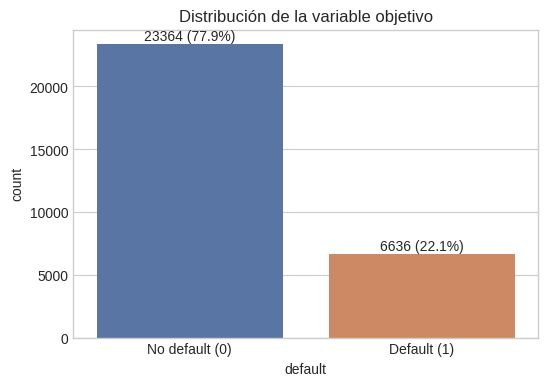

In [ ]:
conteo = df['default'].value_counts()
prop = df['default'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(x='default', data=df, ax=ax, palette=['#4C72B0','#DD8452'])
for i, v in enumerate(conteo):
    ax.text(i, v + 300, f"{v} ({prop[i]:.1f}%)", ha='center')
ax.set_title('Distribución de la variable objetivo')
ax.set_xticklabels(['No default (0)', 'Default (1)'])
plt.show()

### 3.3 Variables categóricas: valores no documentados
Según la documentación, EDUCATION toma valores 1-4 y MARRIAGE 1-3. Verificamos si aparecen otros.

In [ ]:
for col in ['SEX', 'EDUCATION', 'MARRIAGE']:
    print(f"\n{col}:\n", df[col].value_counts().sort_index())

print("\nValores únicos de PAY_0:", sorted(df['PAY_0'].unique()))


SEX:
 SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION:
 EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE:
 MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

Valores únicos de PAY_0: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


**Observaciones sobre variables categóricas:**
- **SEX:** la cartera está compuesta mayoritariamente por mujeres (60,4%) frente a hombres (39,6%).
- **EDUCATION:** 345 registros (1,2%) presentan valores no documentados (0, 5 y 6). Al no poder determinar su significado y ser una proporción mínima, se agruparán en la categoría 4 ("otros").
- **MARRIAGE:** 54 registros presentan el valor 0, no documentado. Se agruparán en la categoría 3 ("otros").
- **PAY_x:** toman valores de -2 a 8; no se observan registros con 9 meses de atraso.

### 3.4 Tasa de default por variable categórica

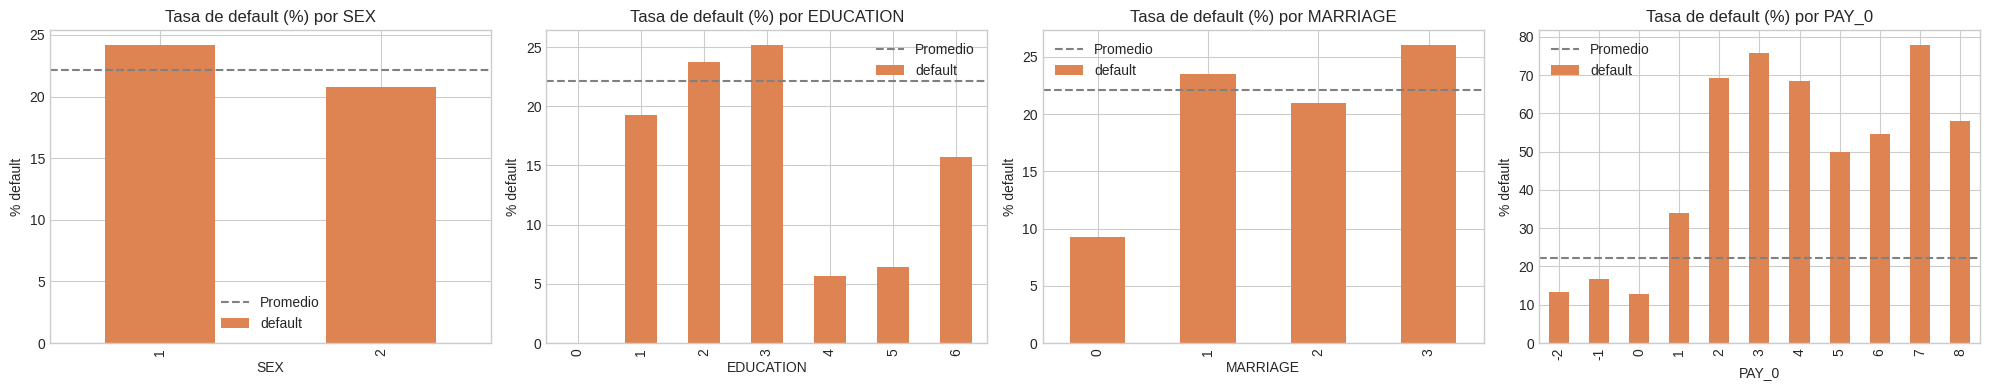

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20,4))
for ax, col in zip(axes, ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0']):
    tasa = df.groupby(col)['default'].mean() * 100
    tasa.plot(kind='bar', ax=ax, color='#DD8452')
    ax.set_title(f'Tasa de default (%) por {col}')
    ax.set_ylabel('% default')
    ax.axhline(df['default'].mean()*100, color='gray', ls='--', label='Promedio')
    ax.legend()
plt.tight_layout()
plt.show()

### 3.5 Distribución de variables numéricas según default

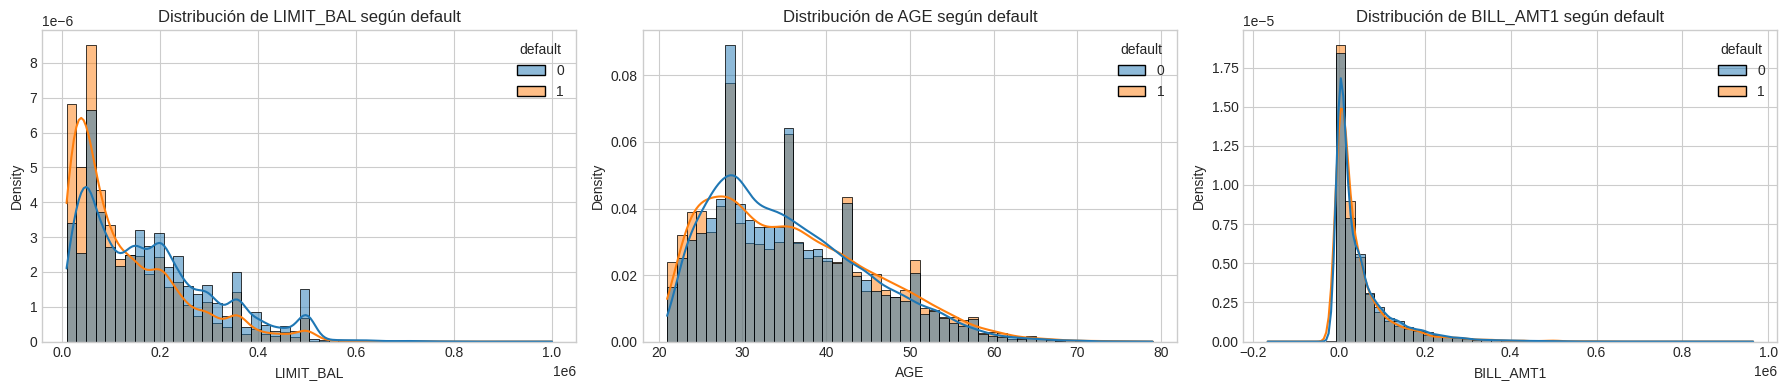

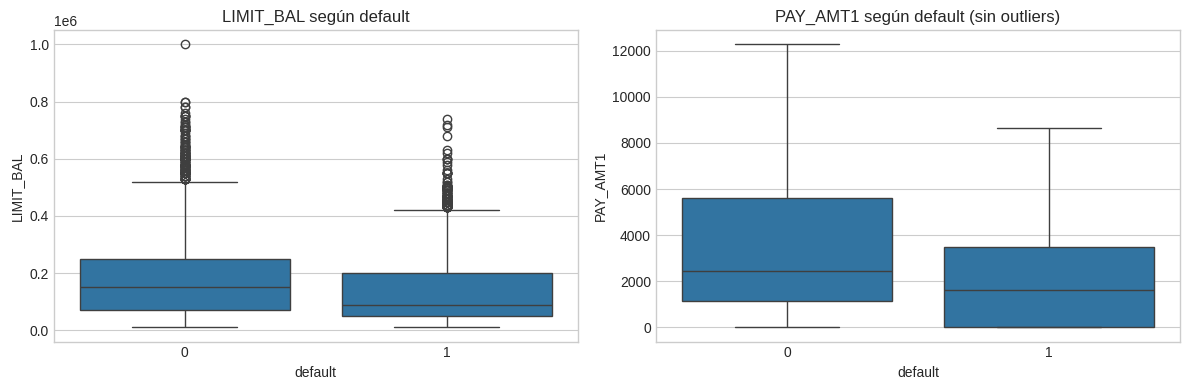

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18,4))
for ax, col in zip(axes, ['LIMIT_BAL', 'AGE', 'BILL_AMT1']):
    sns.histplot(data=df, x=col, hue='default', bins=50, kde=True,
                 stat='density', common_norm=False, ax=ax)
    ax.set_title(f'Distribución de {col} según default')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(x='default', y='LIMIT_BAL', data=df, ax=axes[0])
axes[0].set_title('LIMIT_BAL según default')
sns.boxplot(x='default', y='PAY_AMT1', data=df, ax=axes[1], showfliers=False)
axes[1].set_title('PAY_AMT1 según default (sin outliers)')
plt.tight_layout()
plt.show()

### 3.6 Correlaciones

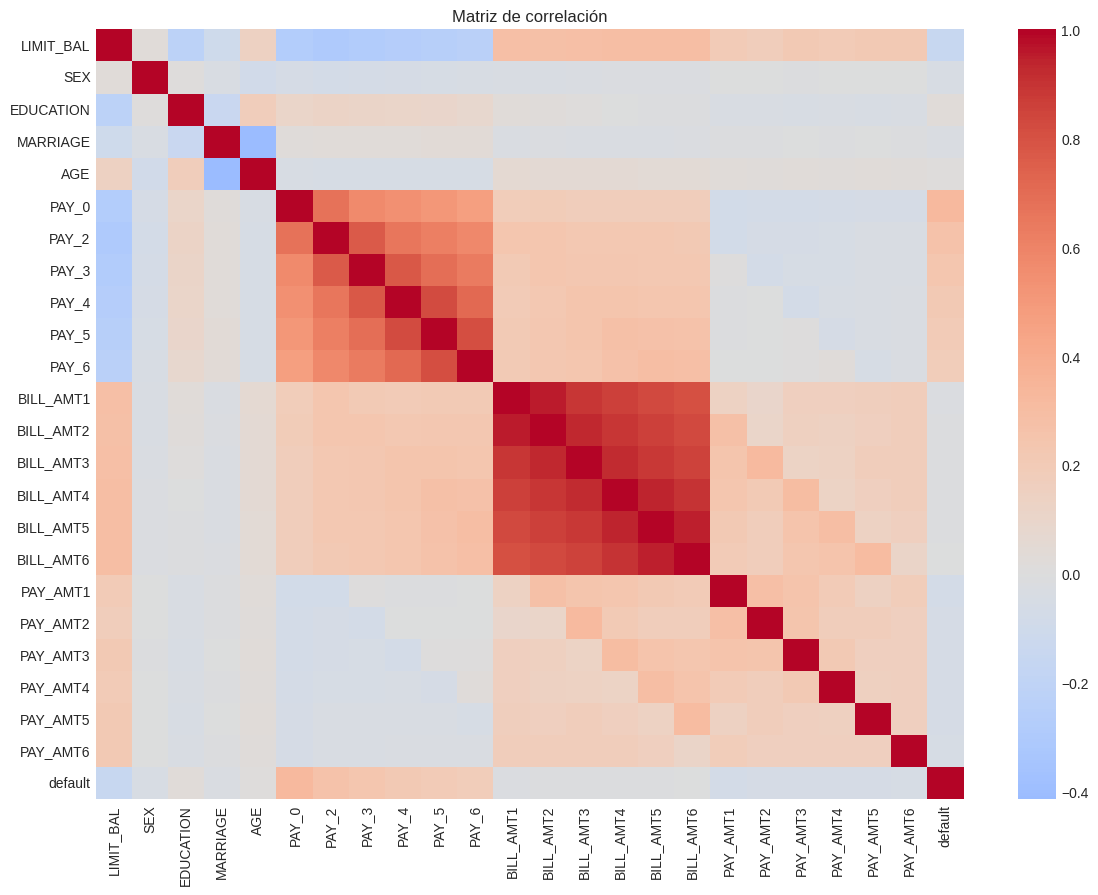

Correlación de cada variable con el target:

PAY_0        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
EDUCATION    0.028
AGE          0.014
BILL_AMT6   -0.005
BILL_AMT5   -0.007
BILL_AMT4   -0.010
BILL_AMT3   -0.014
BILL_AMT2   -0.014
BILL_AMT1   -0.020
MARRIAGE    -0.024
SEX         -0.040
PAY_AMT6    -0.053
PAY_AMT5    -0.055
PAY_AMT3    -0.056
PAY_AMT4    -0.057
PAY_AMT2    -0.059
PAY_AMT1    -0.073
LIMIT_BAL   -0.154
Name: default, dtype: float64


In [ ]:
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Matriz de correlación')
plt.show()

print("Correlación de cada variable con el target:\n")
print(df.corr()['default'].drop('default').sort_values(ascending=False).round(3))

**Observaciones sobre correlaciones:**
- **PAY_0** (estado de pago del último mes) es la variable más correlacionada con el default (r = 0,325), y la correlación decrece con la antigüedad del mes (PAY_6: r = 0,187). Esto respalda preliminarmente la **Hipótesis 1**: el comportamiento de pago reciente es el principal predictor.
- **LIMIT_BAL** presenta correlación negativa (r = -0,154): clientes con mayor límite de crédito, presumiblemente mejor evaluados por la entidad, incumplen menos.
- Los montos facturados (**BILL_AMT**) prácticamente no correlacionan con el target (|r| ≤ 0,02). El monto absoluto de deuda no es informativo por sí solo; la **Hipótesis 2** plantea que sí lo será la deuda **relativa al límite**, lo que se evaluará mediante un ratio de utilización.
- Los montos pagados (**PAY_AMT**) muestran correlación negativa débil (r entre -0,05 y -0,07), en línea con la **Hipótesis 3**, que se evaluará mediante un ratio de pago sobre lo facturado.
- Las variables demográficas (**SEX, EDUCATION, MARRIAGE, AGE**) presentan correlaciones muy bajas (|r| < 0,05), respaldando preliminarmente la **Hipótesis 4**.
- El heatmap evidencia **alta correlación entre las BILL_AMT** de distintos meses (multicolinealidad), lo que refuerza la conveniencia de resumirlas en variables derivadas.
- *Nota:* el coeficiente de Pearson solo captura relaciones lineales; los modelos basados en árboles podrán detectar relaciones no lineales.

### 3.7 Outliers

In [ ]:
num_cols = ['LIMIT_BAL'] + [f'BILL_AMT{i}' for i in range(1,7)] + [f'PAY_AMT{i}' for i in range(1,7)]

outliers = {}
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers[col] = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()

print(pd.Series(outliers, name='Outliers (IQR)').sort_values(ascending=False))
print("\nBILL_AMT negativos (saldo a favor):", (df[[f'BILL_AMT{i}' for i in range(1,7)]] < 0).sum().sum())

PAY_AMT4     2994
PAY_AMT6     2958
PAY_AMT5     2945
PAY_AMT1     2745
BILL_AMT5    2725
PAY_AMT2     2714
BILL_AMT6    2693
BILL_AMT4    2622
PAY_AMT3     2598
BILL_AMT3    2469
BILL_AMT1    2400
BILL_AMT2    2395
LIMIT_BAL     167
Name: Outliers (IQR), dtype: int64

BILL_AMT negativos (saldo a favor): 3932


**Observaciones sobre outliers:**
- Según el criterio IQR, las variables de montos (**BILL_AMT** y **PAY_AMT**) presentan entre 2.400 y 3.000 outliers cada una (8-10% de los registros). **LIMIT_BAL** presenta solo 167 (0,6%).
- Estos valores **no se consideran errores**, sino la cola larga propia de los datos financieros (clientes con deudas o pagos elevados). Eliminarlos implicaría perder una proporción significativa de la muestra y, posiblemente, información relevante para el modelo.
- **Decisión:** se conservan los outliers. Para los modelos lineales se aplicará una transformación logarítmica que reduzca su influencia; los modelos basados en árboles (Random Forest, XGBoost) son robustos a valores extremos por construcción.
- Se registran 3.932 valores negativos en BILL_AMT (sumando los 6 meses), correspondientes a saldos a favor del cliente; se conservan.

### 3.8 Conclusiones del EDA
1. **Calidad de datos:** el dataset no presenta nulos. Se eliminarán 35 duplicados y se agruparán los valores no documentados de EDUCATION (0, 5, 6 → 4) y MARRIAGE (0 → 3).
2. **Desbalance:** el 22,1% de los clientes incurre en default. Se utilizará split estratificado, validación cruzada estratificada y ponderación de clases.
3. **Comportamiento de pago:** el historial de pagos (PAY_x), especialmente el más reciente, es la señal más fuerte disponible.
4. **Montos absolutos poco informativos:** los montos facturados no correlacionan con el default, lo que motiva crear **variables relativas** (utilización del límite, proporción pagada sobre lo facturado) y variables de **tendencia**.
5. **Variables demográficas:** poder predictivo bajo a priori.
6. **Outliers:** se conservan; se tratarán con transformación logarítmica en modelos lineales.
7. **Multicolinealidad:** alta correlación entre las BILL_AMT, que se mitigará con variables resumen.

## 4. Limpieza de datos
Se aplican las decisiones tomadas en el EDA: eliminación de duplicados y reagrupación de categorías no documentadas.

In [ ]:
df_clean = df.copy()

# 1. Eliminar duplicados
filas_antes = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Duplicados eliminados: {filas_antes - len(df_clean)} | Filas restantes: {len(df_clean)}")

# 2. Reagrupar categorías no documentadas
df_clean['EDUCATION'] = df_clean['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df_clean['MARRIAGE'] = df_clean['MARRIAGE'].replace({0: 3})

print("\nEDUCATION:\n", df_clean['EDUCATION'].value_counts().sort_index())
print("\nMARRIAGE:\n", df_clean['MARRIAGE'].value_counts().sort_index())

Duplicados eliminados: 35 | Filas restantes: 29965

EDUCATION:
 EDUCATION
1    10563
2    14019
3     4915
4      468
Name: count, dtype: int64

MARRIAGE:
 MARRIAGE
1    13643
2    15945
3      377
Name: count, dtype: int64


## 5. Ingeniería de atributos
Se crean variables que capturan el comportamiento **relativo** del cliente, ya que el EDA mostró que los montos absolutos son poco informativos.

| Variable nueva | Cálculo | Hipótesis que evalúa |
|---|---|---|
| `UTIL_ULT` | BILL_AMT1 / LIMIT_BAL | H2: utilización del límite en el último mes |
| `UTIL_PROM` | Promedio de BILL_AMT1-6 / LIMIT_BAL | H2: utilización promedio en 6 meses |
| `RATIO_PAGO_PROM` | Promedio de (pago del mes / resumen del mes anterior) | H3: proporción de la deuda que el cliente cancela |
| `MESES_ATRASO` | Cantidad de meses con PAY_x > 0 | H1: frecuencia de atrasos |
| `MAX_ATRASO` | Máximo de PAY_x | H1: gravedad del peor atraso |
| `TENDENCIA_DEUDA` | (BILL_AMT1 − BILL_AMT6) / LIMIT_BAL | Crecimiento de la deuda en el semestre |

**Nota sobre el ratio de pago:** el pago registrado en un mes (PAY_AMTk) cancela el resumen del mes anterior (BILL_AMTk+1). Cuando el resumen es ≤ 0 (sin deuda o saldo a favor), se asigna ratio = 1 (no había nada que pagar). El ratio se acota en 1 para evitar valores extremos por pagos adelantados.

Todas las variables se calculan **fila a fila**, sin usar información de otros registros, por lo que no generan *data leakage* al crearse antes del split.

In [ ]:
bill_cols = [f'BILL_AMT{i}' for i in range(1, 7)]
pay_amt_cols = [f'PAY_AMT{i}' for i in range(1, 7)]
pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

# H2: utilización del límite
df_clean['UTIL_ULT'] = df_clean['BILL_AMT1'] / df_clean['LIMIT_BAL']
df_clean['UTIL_PROM'] = df_clean[bill_cols].mean(axis=1) / df_clean['LIMIT_BAL']

# H3: ratio de pago (PAY_AMTk paga BILL_AMTk+1)
ratios = []
for k in range(1, 6):
    bill_prev = df_clean[f'BILL_AMT{k+1}']
    pago = df_clean[f'PAY_AMT{k}']
    ratio = np.where(bill_prev <= 0, 1, pago / bill_prev.where(bill_prev > 0, 1))
    ratios.append(np.clip(ratio, 0, 1))
df_clean['RATIO_PAGO_PROM'] = np.mean(ratios, axis=0)

# H1: historial de atrasos
df_clean['MESES_ATRASO'] = (df_clean[pay_cols] > 0).sum(axis=1)
df_clean['MAX_ATRASO'] = df_clean[pay_cols].max(axis=1)

# Tendencia de endeudamiento
df_clean['TENDENCIA_DEUDA'] = (df_clean['BILL_AMT1'] - df_clean['BILL_AMT6']) / df_clean['LIMIT_BAL']

nuevas = ['UTIL_ULT', 'UTIL_PROM', 'RATIO_PAGO_PROM', 'MESES_ATRASO', 'MAX_ATRASO', 'TENDENCIA_DEUDA']
df_clean[nuevas].describe().T

,count,mean,std,min,25%,50%,75%,max
UTIL_ULT,29965.0,0.424263,0.411451,-0.619892,0.022300,0.315278,0.830325,6.455300
UTIL_PROM,29965.0,0.373480,0.351867,-0.232590,0.030300,0.285629,0.688454,5.364308
RATIO_PAGO_PROM,29965.0,0.409605,0.400495,0.000000,0.047822,0.196139,0.826924,1.000000
MESES_ATRASO,29965.0,0.834273,1.554821,0.000000,0.000000,0.000000,1.000000,6.000000
MAX_ATRASO,29965.0,0.439146,1.344934,-2.000000,0.000000,0.000000,2.000000,8.000000
TENDENCIA_DEUDA,29965.0,0.105309,0.301525,-1.827300,-0.029231,0.006940,0.181800,5.309500


### 5.1 Validación de las variables creadas
Se compara la correlación de las nuevas variables con el target frente a la de las variables originales que resumen.

MESES_ATRASO       0.398
MAX_ATRASO         0.331
PAY_0              0.325
LIMIT_BAL         -0.154
UTIL_PROM          0.115
RATIO_PAGO_PROM   -0.106
UTIL_ULT           0.086
PAY_AMT1          -0.073
TENDENCIA_DEUDA   -0.024
BILL_AMT1         -0.020
dtype: float64


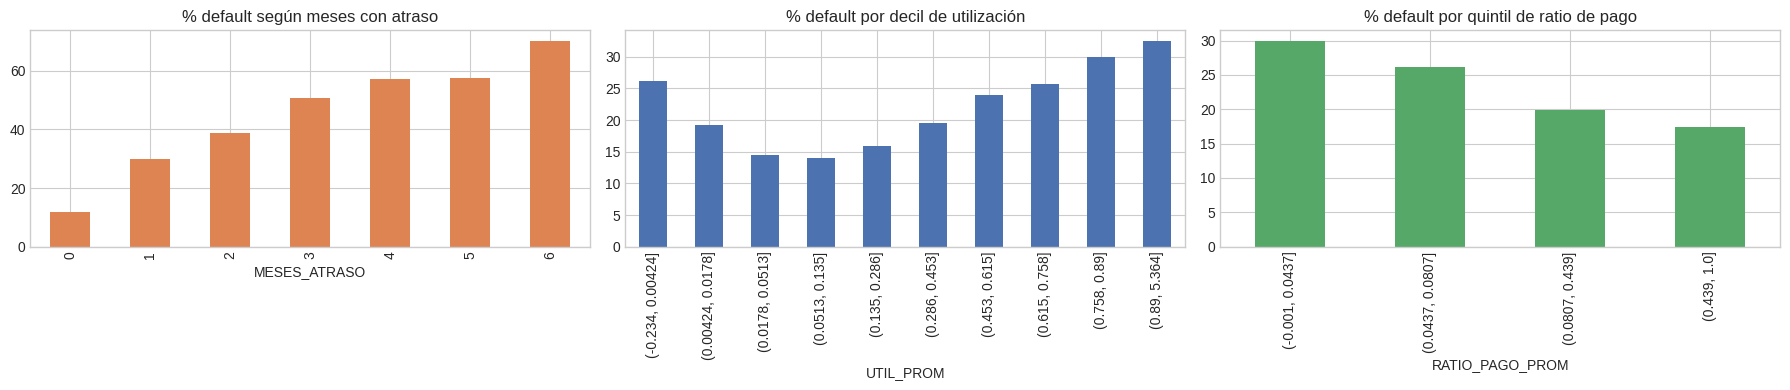

In [ ]:
corr_nuevas = df_clean[nuevas + ['default']].corr()['default'].drop('default')
corr_ref = df_clean[['PAY_0', 'LIMIT_BAL', 'BILL_AMT1', 'PAY_AMT1']].corrwith(df_clean['default'])

comparacion = pd.concat([corr_nuevas, corr_ref]).sort_values(key=abs, ascending=False).round(3)
print(comparacion)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
df_clean.groupby('MESES_ATRASO')['default'].mean().mul(100).plot(kind='bar', ax=axes[0], color='#DD8452')
axes[0].set_title('% default según meses con atraso')
pd.qcut(df_clean['UTIL_PROM'], 10, duplicates='drop').pipe(
    lambda b: df_clean.groupby(b)['default'].mean().mul(100)).plot(kind='bar', ax=axes[1], color='#4C72B0')
axes[1].set_title('% default por decil de utilización')
pd.qcut(df_clean['RATIO_PAGO_PROM'], 5, duplicates='drop').pipe(
    lambda b: df_clean.groupby(b)['default'].mean().mul(100)).plot(kind='bar', ax=axes[2], color='#55A868')
axes[2].set_title('% default por quintil de ratio de pago')
plt.tight_layout()
plt.show()

**Resultados de la ingeniería de atributos:**
- **MESES_ATRASO** (r = 0,398) se convierte en la variable más correlacionada con el default, superando a PAY_0 (r = 0,325). La **frecuencia** de atrasos en el semestre es más informativa que el estado del último mes aislado, reforzando la **Hipótesis 1**. MAX_ATRASO (r = 0,331) también supera a PAY_0.
- **UTIL_PROM** (r = 0,115) presenta una correlación muy superior a la del monto facturado absoluto (BILL_AMT1, r = -0,020). La deuda es informativa cuando se expresa **en relación al límite**, lo que respalda la **Hipótesis 2**. La utilización promedio supera a la del último mes (UTIL_ULT, r = 0,086), por ser una medida más estable.
- **RATIO_PAGO_PROM** (r = -0,106) supera al monto pagado absoluto (PAY_AMT1, r = -0,073): los clientes que cancelan una mayor proporción de su deuda incumplen menos, lo que respalda la **Hipótesis 3**.
- **TENDENCIA_DEUDA** (r = -0,024) no muestra relación lineal con el target. Se conserva para evaluar posibles relaciones no lineales en los modelos de árboles; su aporte se verificará con el análisis SHAP.

## 6. Separación en train y test
Se reserva un 20% de los datos como conjunto de test, **estratificado** por la variable objetivo para preservar la proporción de default (≈22%). El test no se utiliza hasta la evaluación final.

In [ ]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns='default')
y = df_clean['default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape} | default: {y_train.mean():.3f}")
print(f"Test:  {X_test.shape} | default: {y_test.mean():.3f}")

Train: (23972, 29) | default: 0.221
Test:  (5993, 29) | default: 0.221


La proporción de default se mantiene en 22,1% en ambos conjuntos, confirmando la correcta estratificación. Cada conjunto cuenta con 29 variables (23 originales + 6 creadas).

## 7. Preprocesamiento
Se definen dos preprocesadores, integrados luego en `Pipeline` para que todas las transformaciones se ajusten **solo con datos de entrenamiento** (evitando *data leakage*):

- **Para modelos lineales:** One-Hot Encoding en categóricas; transformación logarítmica con signo en montos (reduce asimetría y outliers, admite negativos); estandarización de todas las numéricas.
- **Para modelos de árboles:** One-Hot Encoding en categóricas; numéricas sin transformar (los árboles son invariantes a escala y robustos a outliers).

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline

cat_cols = ['SEX', 'EDUCATION', 'MARRIAGE']
monto_cols = ['LIMIT_BAL'] + bill_cols + pay_amt_cols
otras_num = ['AGE'] + pay_cols + nuevas

def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

prep_lineal = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
    ('montos', Pipeline([('log', FunctionTransformer(signed_log)),
                         ('scaler', StandardScaler())]), monto_cols),
    ('num', StandardScaler(), otras_num)
])

prep_arboles = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', 'passthrough', monto_cols + otras_num)
])

print(f"Categóricas: {len(cat_cols)} | Montos: {len(monto_cols)} | Otras numéricas: {len(otras_num)}")

Categóricas: 3 | Montos: 13 | Otras numéricas: 13


## 8. Modelos base
Se entrenan cuatro modelos con hiperparámetros por defecto, más un modelo trivial (*baseline*) como referencia mínima:

| Modelo | Preprocesador | Manejo del desbalance |
|---|---|---|
| Dummy (clase mayoritaria) | — | — |
| Regresión Logística | Lineal | `class_weight='balanced'` |
| Árbol de Decisión | Árboles | `class_weight='balanced'` |
| Random Forest | Árboles | `class_weight='balanced'` |
| XGBoost | Árboles | `scale_pos_weight` = negativos / positivos |

Se evalúan con **validación cruzada estratificada de 5 folds** sobre el conjunto de entrenamiento, reportando ROC AUC (métrica principal), recall, precision y F1 de la clase positiva.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['roc_auc', 'recall', 'precision', 'f1']

ratio_desbalance = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight para XGBoost: {ratio_desbalance:.2f}")

modelos = {
    'Dummy': Pipeline([('prep', prep_arboles),
                       ('model', DummyClassifier(strategy='most_frequent'))]),
    'Regresión Logística': Pipeline([('prep', prep_lineal),
                       ('model', LogisticRegression(class_weight='balanced', max_iter=1000,
                                                    random_state=RANDOM_STATE))]),
    'Árbol de Decisión': Pipeline([('prep', prep_arboles),
                       ('model', DecisionTreeClassifier(class_weight='balanced',
                                                        random_state=RANDOM_STATE))]),
    'Random Forest': Pipeline([('prep', prep_arboles),
                       ('model', RandomForestClassifier(class_weight='balanced', n_estimators=200,
                                                        n_jobs=-1, random_state=RANDOM_STATE))]),
    'XGBoost': Pipeline([('prep', prep_arboles),
                       ('model', XGBClassifier(scale_pos_weight=ratio_desbalance, eval_metric='logloss',
                                               n_jobs=-1, random_state=RANDOM_STATE))])
}

scale_pos_weight para XGBoost: 3.52


In [ ]:
resultados = {}
for nombre, pipe in modelos.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    resultados[nombre] = scores
    print(f"{nombre:22s} | AUC: {scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}")

tabla_base = pd.DataFrame({
    nombre: {
        'ROC AUC': s['test_roc_auc'].mean(),
        'AUC (std)': s['test_roc_auc'].std(),
        'Recall': s['test_recall'].mean(),
        'Precision': s['test_precision'].mean(),
        'F1': s['test_f1'].mean(),
        'Tiempo (s)': s['fit_time'].mean()
    } for nombre, s in resultados.items()
}).T.round(4).sort_values('ROC AUC', ascending=False)

tabla_base

Dummy                  | AUC: 0.5000 ± 0.0000
Regresión Logística    | AUC: 0.7633 ± 0.0110
Árbol de Decisión      | AUC: 0.6151 ± 0.0091
Random Forest          | AUC: 0.7726 ± 0.0071
XGBoost                | AUC: 0.7604 ± 0.0082


,ROC AUC,AUC (std),Recall,Precision,F1,Tiempo (s)
Random Forest,0.7726,0.0071,0.3503,0.6509,0.4554,15.3613
Regresión Logística,0.7633,0.0110,0.6242,0.4557,0.5268,0.2190
XGBoost,0.7604,0.0082,0.5628,0.4686,0.5114,0.7516
Árbol de Decisión,0.6151,0.0091,0.4048,0.3974,0.4011,0.9409
Dummy,0.5000,0.0000,0.0000,0.0000,0.0000,0.0470


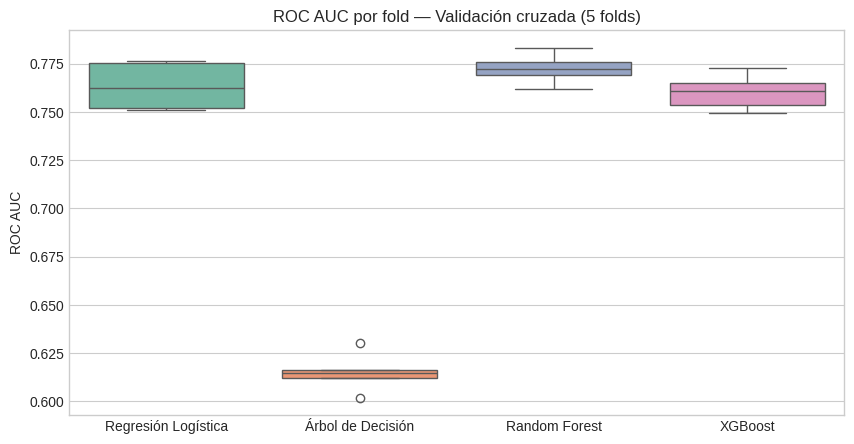

In [ ]:
auc_folds = pd.DataFrame({n: s['test_roc_auc'] for n, s in resultados.items() if n != 'Dummy'})

plt.figure(figsize=(10, 5))
sns.boxplot(data=auc_folds, palette='Set2')
plt.title('ROC AUC por fold — Validación cruzada (5 folds)')
plt.ylabel('ROC AUC')
plt.show()

**Análisis de modelos base:**
- Todos los modelos superan ampliamente al baseline (AUC 0,50). Los tres modelos principales obtienen un ROC AUC similar (0,760–0,773), dentro del rango reportado habitualmente para este dataset (≈0,77–0,79).
- **Random Forest** obtiene el mayor AUC (0,773) y la menor variabilidad entre folds, pero un **recall bajo (0,35)** con el umbral por defecto: el ajuste por `class_weight` pierde efecto cuando los árboles crecen sin restricción de profundidad.
- **Regresión Logística** alcanza un AUC muy competitivo (0,763) con el **mejor recall (0,62) y F1 (0,53)**, y un tiempo de entrenamiento ~70 veces menor que Random Forest. Su buen desempeño se apoya en la ingeniería de atributos y la transformación logarítmica.
- **XGBoost** con hiperparámetros por defecto (profundidad 6, learning rate 0,3) queda tercero, lo que sugiere sobreajuste; es el modelo con mayor margen de mejora mediante optimización.
- **Árbol de Decisión** sobreajusta notoriamente (AUC 0,615) al no tener límite de profundidad; **se descarta**.

**Decisión:** se optimizan Regresión Logística, Random Forest y XGBoost.

## 9. Optimización de hiperparámetros
- **Regresión Logística:** `GridSearchCV` (espacio de búsqueda reducido, se prueban todas las combinaciones).
- **Random Forest y XGBoost:** `RandomizedSearchCV` (espacios de búsqueda amplios; se evalúa una muestra aleatoria de combinaciones, más eficiente en tiempo).

En todos los casos se optimiza **ROC AUC** con la misma validación cruzada estratificada de 5 folds.

In [ ]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

param_lr = {
    'model__C': [0.001, 0.01, 0.1, 1, 10],
    'model__penalty': ['l1', 'l2']
}

pipe_lr = Pipeline([('prep', prep_lineal),
                    ('model', LogisticRegression(class_weight='balanced', solver='liblinear',
                                                 max_iter=1000, random_state=RANDOM_STATE))])

grid_lr = GridSearchCV(pipe_lr, param_lr, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_lr.fit(X_train, y_train)

print("Mejores parámetros LR:", grid_lr.best_params_)
print(f"Mejor AUC (CV): {grid_lr.best_score_:.4f}")

Mejores parámetros LR: {'model__C': 0.1, 'model__penalty': 'l1'}
Mejor AUC (CV): 0.7636


In [ ]:
param_xgb = {
    'model__n_estimators': [200, 300, 500, 800],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__max_depth': [3, 4, 5, 6],
    'model__min_child_weight': [1, 3, 5, 10],
    'model__subsample': [0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'model__gamma': [0, 0.1, 0.5, 1],
    'model__reg_lambda': [1, 5, 10]
}

pipe_xgb = Pipeline([('prep', prep_arboles),
                     ('model', XGBClassifier(scale_pos_weight=ratio_desbalance, eval_metric='logloss',
                                             n_jobs=-1, random_state=RANDOM_STATE))])

rand_xgb = RandomizedSearchCV(pipe_xgb, param_xgb, n_iter=40, cv=cv, scoring='roc_auc',
                              n_jobs=-1, random_state=RANDOM_STATE)
rand_xgb.fit(X_train, y_train)

print("Mejores parámetros XGB:", rand_xgb.best_params_)
print(f"Mejor AUC (CV): {rand_xgb.best_score_:.4f}")

Mejores parámetros XGB: {'model__subsample': 0.9, 'model__reg_lambda': 5, 'model__n_estimators': 500, 'model__min_child_weight': 5, 'model__max_depth': 5, 'model__learning_rate': 0.01, 'model__gamma': 0.5, 'model__colsample_bytree': 0.7}
Mejor AUC (CV): 0.7894


In [ ]:
param_rf = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [6, 8, 10, 15, None],
    'model__min_samples_leaf': [1, 5, 10, 20, 50],
    'model__max_features': ['sqrt', 'log2', 0.5],
    'model__class_weight': ['balanced', 'balanced_subsample']
}

pipe_rf = Pipeline([('prep', prep_arboles),
                    ('model', RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE))])

rand_rf = RandomizedSearchCV(pipe_rf, param_rf, n_iter=15, cv=cv, scoring='roc_auc',
                             n_jobs=-1, random_state=RANDOM_STATE)
rand_rf.fit(X_train, y_train)

print("Mejores parámetros RF:", rand_rf.best_params_)
print(f"Mejor AUC (CV): {rand_rf.best_score_:.4f}")

Mejores parámetros RF: {'model__n_estimators': 200, 'model__min_samples_leaf': 50, 'model__max_features': 0.5, 'model__max_depth': None, 'model__class_weight': 'balanced_subsample'}
Mejor AUC (CV): 0.7878


In [ ]:
comparacion_opt = pd.DataFrame({
    'AUC base': [tabla_base.loc['Regresión Logística', 'ROC AUC'],
                 tabla_base.loc['Random Forest', 'ROC AUC'],
                 tabla_base.loc['XGBoost', 'ROC AUC']],
    'AUC optimizado': [grid_lr.best_score_, rand_rf.best_score_, rand_xgb.best_score_]
}, index=['Regresión Logística', 'Random Forest', 'XGBoost'])

comparacion_opt['Mejora'] = comparacion_opt['AUC optimizado'] - comparacion_opt['AUC base']
comparacion_opt.round(4).sort_values('AUC optimizado', ascending=False)

,AUC base,AUC optimizado,Mejora
XGBoost,0.7604,0.7894,0.0290
Random Forest,0.7726,0.7878,0.0152
Regresión Logística,0.7633,0.7636,0.0003


**Análisis de la optimización:**
- **XGBoost** obtiene la mayor mejora (+0,029) y el mejor AUC (0,789). La configuración óptima combina un *learning rate* bajo (0,01) con más árboles (500), menor profundidad (5) y mayor regularización (`gamma`=0,5, `reg_lambda`=5, `min_child_weight`=5), confirmando que los parámetros por defecto sobreajustaban.
- **Random Forest** mejora +0,015, principalmente por `min_samples_leaf`=50, que restringe el tamaño mínimo de las hojas y actúa como regularización.
- **Regresión Logística** no mejora significativamente (+0,0003): el modelo alcanzó el techo de su capacidad lineal. La penalización L1 con C=0,1 realiza selección implícita de variables.
- La diferencia entre XGBoost y Random Forest (0,0016) es menor que la variabilidad entre folds (≈0,007), por lo que ambos se consideran equivalentes en validación cruzada. La selección final se definirá con el desempeño en test y criterios de negocio.

## 10. Evaluación en el conjunto de test
Se evalúan los tres modelos optimizados sobre el conjunto de test, nunca utilizado hasta ahora. Se compara además el AUC en train para detectar sobreajuste.

In [ ]:
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, fbeta_score, recall_score,
                             precision_score, f1_score, ConfusionMatrixDisplay)

modelos_opt = {
    'XGBoost': rand_xgb.best_estimator_,
    'Random Forest': rand_rf.best_estimator_,
    'Regresión Logística': grid_lr.best_estimator_
}

eval_test = {}
for nombre, modelo in modelos_opt.items():
    p_train = modelo.predict_proba(X_train)[:, 1]
    p_test = modelo.predict_proba(X_test)[:, 1]
    eval_test[nombre] = {
        'AUC train': roc_auc_score(y_train, p_train),
        'AUC test': roc_auc_score(y_test, p_test),
        'Recall (0.5)': recall_score(y_test, p_test >= 0.5),
        'Precision (0.5)': precision_score(y_test, p_test >= 0.5),
        'F1 (0.5)': f1_score(y_test, p_test >= 0.5)
    }

tabla_test = pd.DataFrame(eval_test).T
tabla_test['Brecha train-test'] = tabla_test['AUC train'] - tabla_test['AUC test']
tabla_test.round(4).sort_values('AUC test', ascending=False)

,AUC train,AUC test,Recall (0.5),Precision (0.5),F1 (0.5),Brecha train-test
XGBoost,0.8257,0.7798,0.6290,0.4595,0.5310,0.0458
Random Forest,0.8572,0.7758,0.5980,0.4818,0.5336,0.0814
Regresión Logística,0.7662,0.7567,0.6063,0.4494,0.5162,0.0095


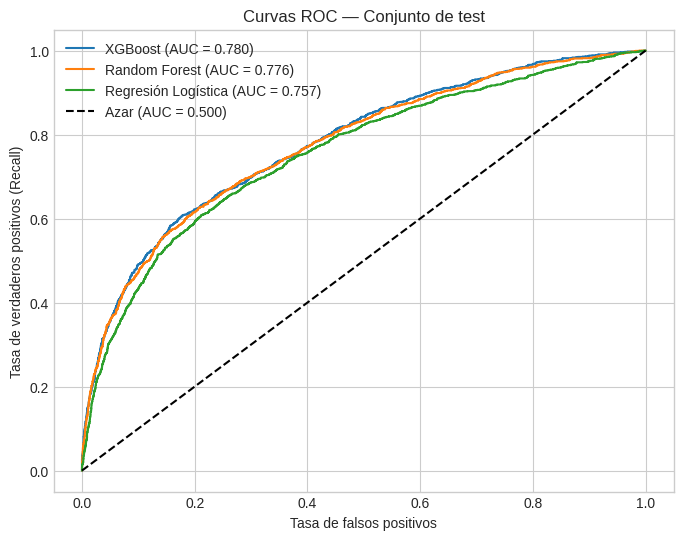

In [ ]:
plt.figure(figsize=(8, 6))
for nombre, modelo in modelos_opt.items():
    p = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Azar (AUC = 0.500)')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos (Recall)')
plt.title('Curvas ROC — Conjunto de test')
plt.legend()
plt.show()

**Resultados en test y selección del modelo:**
- **XGBoost** obtiene el mayor AUC en test (0,780), consistente con su AUC en validación cruzada (0,789), lo que confirma su capacidad de generalización.
- **Random Forest** alcanza un AUC similar (0,776) pero con una brecha train-test casi el doble que XGBoost (0,081 vs 0,046), indicando mayor sobreajuste.
- **Regresión Logística** prácticamente no sobreajusta (brecha 0,010), pero su desempeño es inferior (0,757) por las limitaciones de un modelo lineal.

**Modelo seleccionado: XGBoost**, por combinar el mejor poder discriminante en datos no vistos, un sobreajuste controlado, el mejor recall con el umbral por defecto y compatibilidad eficiente con SHAP para su interpretación.

## 11. Selección del umbral de decisión
El umbral por defecto (0,5) no necesariamente es el óptimo para el negocio. Dado que **un falso negativo (otorgar crédito a quien no paga) es más costoso que un falso positivo (revisar a un buen pagador)**, se elige el umbral que maximiza el **F2-score**, métrica que pondera el recall el doble que la precisión.

Para no contaminar el test, el umbral se determina con **predicciones de validación cruzada sobre train** (`cross_val_predict`).

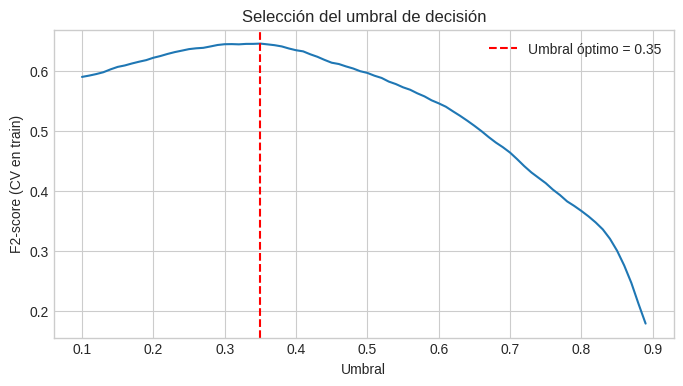

Umbral óptimo: 0.35 | F2 en CV: 0.6456


In [ ]:
from sklearn.model_selection import cross_val_predict

modelo_final = rand_xgb.best_estimator_

p_oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

umbrales = np.arange(0.10, 0.90, 0.01)
f2_scores = [fbeta_score(y_train, p_oof >= u, beta=2) for u in umbrales]
umbral_opt = umbrales[np.argmax(f2_scores)]

plt.figure(figsize=(8, 4))
plt.plot(umbrales, f2_scores)
plt.axvline(umbral_opt, color='red', ls='--', label=f'Umbral óptimo = {umbral_opt:.2f}')
plt.xlabel('Umbral')
plt.ylabel('F2-score (CV en train)')
plt.title('Selección del umbral de decisión')
plt.legend()
plt.show()

print(f"Umbral óptimo: {umbral_opt:.2f} | F2 en CV: {max(f2_scores):.4f}")

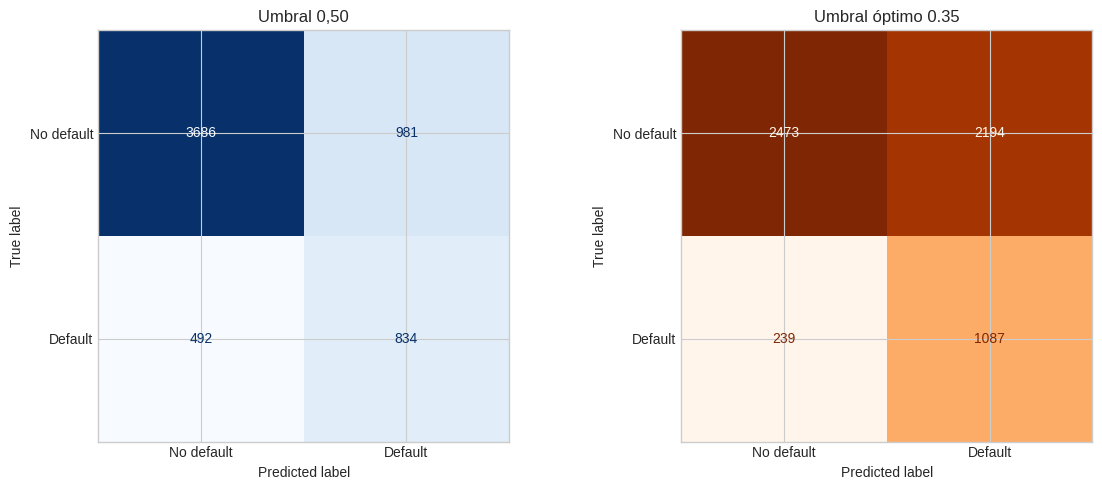

=== Umbral 0,50 ===
              precision    recall  f1-score   support

  No default      0.882     0.790     0.833      4667
     Default      0.460     0.629     0.531      1326

    accuracy                          0.754      5993
   macro avg      0.671     0.709     0.682      5993
weighted avg      0.789     0.754     0.767      5993

=== Umbral 0.35 ===
              precision    recall  f1-score   support

  No default      0.912     0.530     0.670      4667
     Default      0.331     0.820     0.472      1326

    accuracy                          0.594      5993
   macro avg      0.622     0.675     0.571      5993
weighted avg      0.783     0.594     0.626      5993



In [ ]:
p_test_final = modelo_final.predict_proba(X_test)[:, 1]
pred_05 = (p_test_final >= 0.5).astype(int)
pred_opt = (p_test_final >= umbral_opt).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_05),
                       display_labels=['No default', 'Default']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Umbral 0,50')
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_opt),
                       display_labels=['No default', 'Default']).plot(ax=axes[1], cmap='Oranges', colorbar=False)
axes[1].set_title(f'Umbral óptimo {umbral_opt:.2f}')
plt.tight_layout()
plt.show()

print("=== Umbral 0,50 ===")
print(classification_report(y_test, pred_05, target_names=['No default', 'Default'], digits=3))
print(f"=== Umbral {umbral_opt:.2f} ===")
print(classification_report(y_test, pred_opt, target_names=['No default', 'Default'], digits=3))

**Análisis del umbral de decisión:**

| | Umbral 0,50 | Umbral 0,35 |
|---|---|---|
| Recall (morosos detectados) | 62,9% (≈834 de 1.326) | 82,0% (≈1.087 de 1.326) |
| Precisión (alertas correctas) | 46,0% | 33,1% |
| Buenos pagadores marcados como riesgo | ≈21% (≈980) | ≈47% (≈2.193) |

Reducir el umbral a 0,35 permite detectar ≈250 morosos adicionales, a costa de ≈1.200 falsas alarmas adicionales (≈5 por cada moroso extra detectado). La caída en accuracy (0,754 → 0,594) no es relevante para este problema, dado el desbalance de clases.

**Recomendación de negocio:** el umbral debe definirse según la acción asociada a la alerta:
- **Acciones preventivas de bajo costo** (recordatorios, contacto telefónico): umbral 0,35, priorizando la detección.
- **Acciones restrictivas** (reducción de límite, bloqueo): umbral 0,50 o superior, para no afectar a buenos pagadores.

Una alternativa operativa es utilizar **ambos umbrales como segmentación de riesgo**: riesgo alto (≥ 0,50), riesgo medio (0,35–0,50) y riesgo bajo (< 0,35), asignando a cada segmento una acción distinta.

## 12. Explicabilidad del modelo con SHAP
Se utiliza SHAP (*SHapley Additive exPlanations*) para interpretar el modelo XGBoost: cuánto aporta cada variable a la predicción, tanto a nivel global (todo el conjunto de test) como individual (un cliente específico). Esto permite validar las hipótesis planteadas y justificar las decisiones del modelo ante el negocio.

In [ ]:
import shap

prep_fit = modelo_final.named_steps['prep']
xgb_fit = modelo_final.named_steps['model']

X_test_trans = prep_fit.transform(X_test)
feature_names = [f.split('__', 1)[1] for f in prep_fit.get_feature_names_out()]
X_test_shap = pd.DataFrame(X_test_trans, columns=feature_names, index=X_test.index)

explainer = shap.TreeExplainer(xgb_fit)
shap_values = explainer(X_test_shap)
print("SHAP values calculados:", shap_values.shape)

SHAP values calculados: (5993, 35)


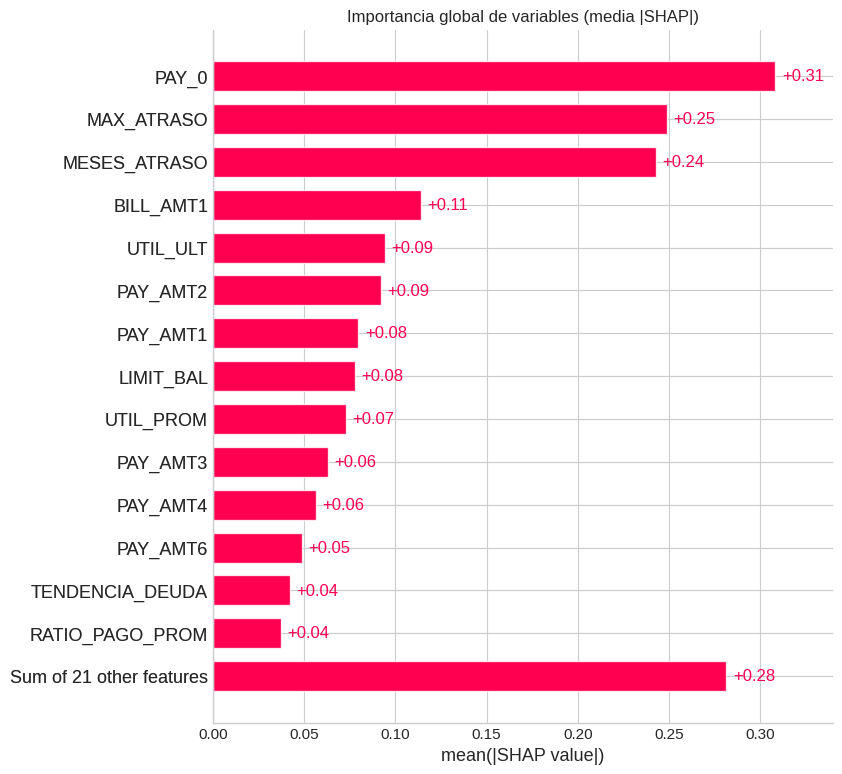

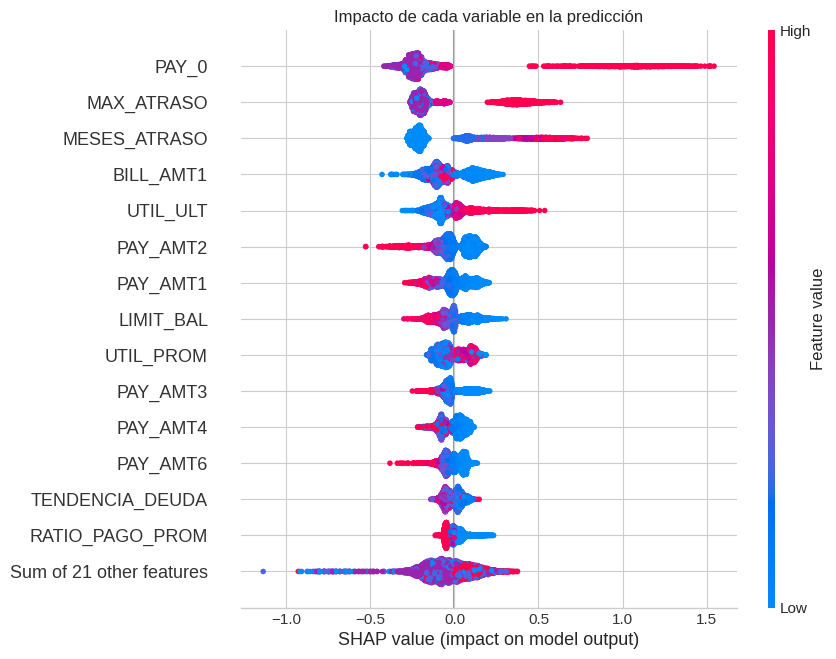

In [ ]:
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title('Importancia global de variables (media |SHAP|)')
plt.show()

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title('Impacto de cada variable en la predicción')
plt.show()

In [ ]:
importancia = pd.DataFrame({
    'Variable': feature_names,
    'Media |SHAP|': np.abs(shap_values.values).mean(axis=0)
}).sort_values('Media |SHAP|', ascending=False).reset_index(drop=True)

importancia['Tipo'] = importancia['Variable'].apply(
    lambda v: 'Creada' if v in nuevas else
              'Demográfica' if v.split('_')[0] in ['SEX', 'EDUCATION', 'MARRIAGE', 'AGE'] else 'Original')

importancia.head(15).round(4)

,Variable,Media |SHAP|,Tipo
0,PAY_0,0.3081,Original
1,MAX_ATRASO,0.2486,Creada
2,MESES_ATRASO,0.2428,Creada
3,BILL_AMT1,0.1139,Original
4,UTIL_ULT,0.0942,Creada
5,PAY_AMT2,0.0919,Original
6,PAY_AMT1,0.0796,Original
7,LIMIT_BAL,0.0777,Original
8,UTIL_PROM,0.0728,Creada
9,PAY_AMT3,0.0631,Original


**Validación de hipótesis con SHAP:**

| Hipótesis | Resultado | Evidencia |
|---|---|---|
| **H1:** el historial de atrasos reciente es el principal predictor | ✅ **Confirmada** | Las tres variables más importantes son de atrasos: PAY_0, MAX_ATRASO y MESES_ATRASO |
| **H2:** la utilización del límite predice el default | ✅ **Confirmada** | UTIL_ULT (5ª) y UTIL_PROM (9ª) entre las más relevantes |
| **H3:** pagar una baja proporción de lo facturado aumenta el riesgo | ✅ **Confirmada (efecto no lineal)** | Pagar menos del ≈5% de lo facturado eleva el riesgo y pagar más del 80% lo reduce. Los montos pagados absolutos (PAY_AMT1, PAY_AMT2) tienen además alta importancia global |
| **H4:** las variables demográficas tienen bajo poder predictivo | ✅ **Confirmada** | Ninguna variable demográfica figura entre las 15 más importantes |

**Hallazgos adicionales:**
- **Las 6 variables creadas figuran entre las 15 más importantes**, validando la ingeniería de atributos.
- **BILL_AMT1** ocupa el 4° lugar pese a su correlación lineal prácticamente nula con el target (r = -0,020): su efecto es **no lineal** o depende de interacciones con otras variables (como el límite de crédito), algo que un modelo de árboles puede capturar y la correlación de Pearson no.
- **TENDENCIA_DEUDA**, sin correlación lineal con el target, aporta al modelo (13ª), lo que justifica haberla conservado.
- *Nota metodológica:* PAY_0, MAX_ATRASO y MESES_ATRASO están correlacionadas entre sí; SHAP reparte la importancia entre variables correlacionadas, por lo que el peso conjunto del historial de atrasos es mayor que el de cada una por separado.

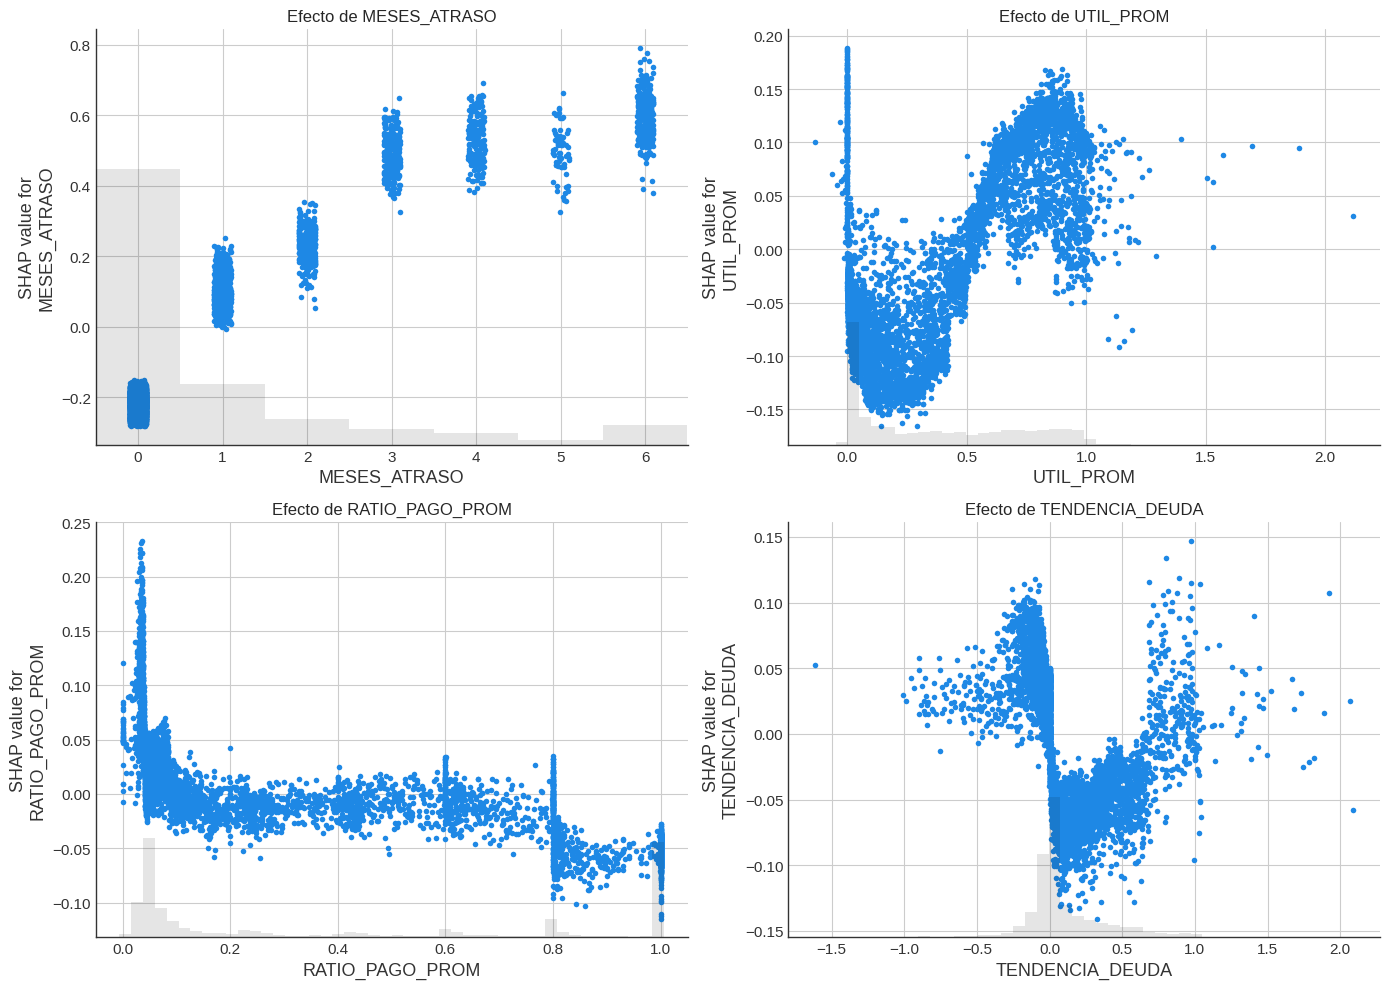

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, var in zip(axes.flat, ['MESES_ATRASO', 'UTIL_PROM', 'RATIO_PAGO_PROM', 'TENDENCIA_DEUDA']):
    shap.plots.scatter(shap_values[:, var], ax=ax, show=False)
    ax.set_title(f'Efecto de {var}')
plt.tight_layout()
plt.show()

**Efectos de las variables clave (gráficos de dependencia SHAP):**
- **MESES_ATRASO:** efecto creciente y escalonado. Sin atrasos reduce el riesgo; cada mes adicional lo incrementa, con un **salto marcado entre 2 y 3 meses de atraso**, que funciona como umbral crítico de riesgo.
- **UTIL_PROM:** relación **en forma de U**. La utilización baja (≈5%–40%) es la de menor riesgo; a partir de ≈50% el riesgo crece fuertemente, con máximo entre 80% y 100% del límite. Los clientes con utilización nula también presentan riesgo elevado.
- **RATIO_PAGO_PROM:** efecto de **umbral**. Pagar menos del ≈5% de lo facturado (compatible con el pago mínimo) eleva marcadamente el riesgo; entre 10% y 80% el efecto es neutro; pagar el 80% o más lo reduce.
- **TENDENCIA_DEUDA:** relación **en forma de V**. Un crecimiento moderado de la deuda se asocia al menor riesgo (uso habitual de la tarjeta), mientras que tanto el crecimiento fuerte (sobreendeudamiento) como la reducción de la deuda lo incrementan. Al actuar los dos extremos en la misma dirección, la correlación lineal resulta prácticamente nula (r = -0,024), aunque la variable sí aporta información.

Estos efectos no lineales explican por qué las correlaciones de Pearson subestimaban la relevancia de varias variables y por qué los modelos de árboles superan a la Regresión Logística.

Cliente de mayor riesgo — probabilidad: 0.947 | default real: 1


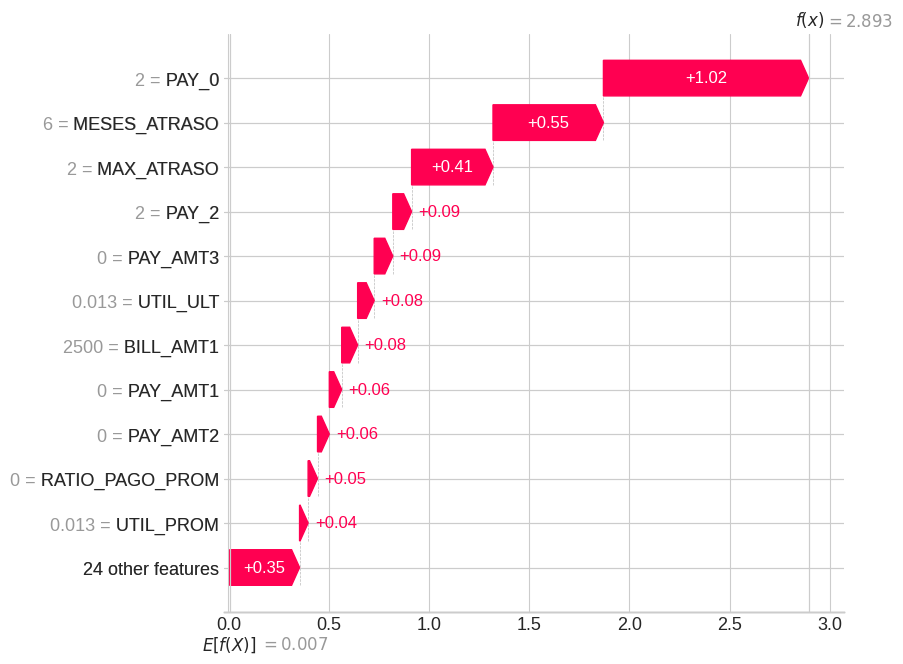

Cliente de menor riesgo — probabilidad: 0.078 | default real: 1


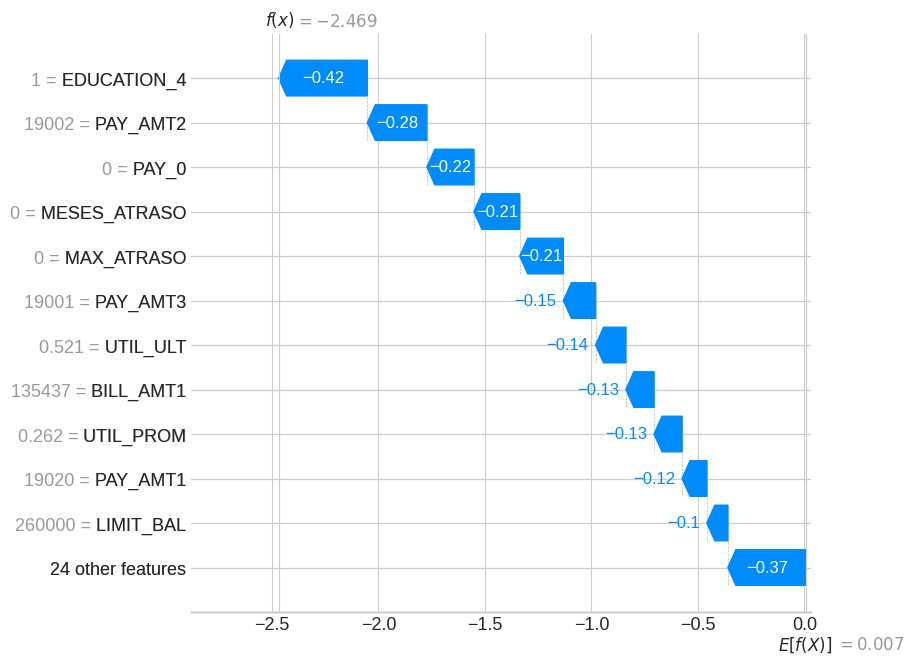

In [ ]:
p_test_final = modelo_final.predict_proba(X_test)[:, 1]
idx_alto = np.argmax(p_test_final)
idx_bajo = np.argmin(p_test_final)

print(f"Cliente de mayor riesgo — probabilidad: {p_test_final[idx_alto]:.3f} | default real: {y_test.iloc[idx_alto]}")
shap.plots.waterfall(shap_values[idx_alto], max_display=12)

print(f"Cliente de menor riesgo — probabilidad: {p_test_final[idx_bajo]:.3f} | default real: {y_test.iloc[idx_bajo]}")
shap.plots.waterfall(shap_values[idx_bajo], max_display=12)

**Cliente de mayor riesgo** (probabilidad estimada ≈ 94,7% | default real: 1):
El riesgo se explica principalmente por el historial de atrasos: atraso de 2 meses en el último período (PAY_0 = 2, +1,02), atrasos en los 6 meses observados (MESES_ATRASO = 6, +0,55) y máximo atraso de 2 meses (+0,41). A esto se suma la **ausencia total de pagos** en los últimos meses (PAY_AMT1-3 = 0 y RATIO_PAGO_PROM = 0).

Un aspecto destacable es que el cliente registra una **deuda muy baja** (2.500; utilización del 1,3%), y aun así es el de mayor riesgo del conjunto de test. Esto ilustra que el riesgo depende del **comportamiento de pago** y no del monto adeudado, y coincide con el pico de riesgo en utilización nula observado en el gráfico de dependencia de UTIL_PROM: una utilización casi nula combinada con falta de pago es característica de una cuenta abandonada. Este tipo de interacción no puede ser capturada por un modelo lineal, lo que explica la superioridad de XGBoost.

**Cliente de menor riesgo** (probabilidad estimada ≈ 7,8%):
El modelo parte del valor base (0,007 en log-odds) y todas las variables reducen el riesgo: ausencia total de atrasos (PAY_0, MESES_ATRASO y MAX_ATRASO = 0), pagos elevados y constantes (≈19.000 mensuales), utilización promedio moderada (26%, dentro de la zona de menor riesgo) y un límite de crédito alto (260.000).

El factor individual de mayor peso es **EDUCATION_4** (categoría "otros", que agrupa valores no documentados). Si bien las variables demográficas tienen baja importancia global, esta categoría minoritaria tiene un efecto fuerte cuando está presente. Dado que su significado es incierto, este efecto debe interpretarse con cautela.

*Nota:* el valor base equivale a ≈50% de probabilidad (y no al 22% real) debido al uso de `scale_pos_weight`, que equilibra las clases durante el entrenamiento. Las probabilidades del modelo son válidas para **ordenar clientes por riesgo**, pero no están calibradas; una calibración posterior (p. ej. `CalibratedClassifierCV`) sería necesaria si se requirieran probabilidades reales.

## 13. Conclusiones

### Resultados
- Se desarrolló un modelo de clasificación para predecir el default de clientes de tarjetas de crédito. El modelo seleccionado, **XGBoost optimizado**, alcanza un **ROC AUC de 0,780 en test** (0,789 en validación cruzada), dentro del rango reportado para este dataset.
- La **ingeniería de atributos** fue determinante: las 6 variables creadas figuran entre las 15 más importantes del modelo, y MESES_ATRASO superó a todas las variables originales en correlación con el target.
- La **optimización de hiperparámetros** mejoró el AUC de XGBoost en 0,029, principalmente mediante regularización.
- Con un **umbral de 0,35**, el modelo detecta el **82% de los morosos**, frente al 63% con el umbral por defecto.

### Validación de hipótesis
Se confirmaron las cuatro hipótesis (H3 con efecto no lineal): el historial de atrasos es el principal predictor, la utilización relativa del límite y la proporción pagada son informativas, y las variables demográficas tienen bajo poder predictivo.

### Recomendaciones para el negocio
1. **Segmentar la cartera por riesgo** usando dos umbrales: alto (≥ 0,50), medio (0,35–0,50) y bajo (< 0,35), con acciones diferenciadas (restrictivas, preventivas y ninguna, respectivamente).
2. **Monitorear especialmente a clientes con 3 o más meses de atraso**, umbral a partir del cual el riesgo se incrementa marcadamente.
3. **No evaluar el riesgo solo por el monto adeudado:** clientes con deuda baja pero sin pagos son de alto riesgo.

### Limitaciones
- Los datos corresponden a Taiwán en 2005; su aplicación a otros mercados o períodos requeriría reentrenamiento.
- Las probabilidades no están calibradas (efecto de `scale_pos_weight`): sirven para ordenar clientes, no como probabilidades reales.
- Algunas categorías (EDUCATION "otros", valores -2 y 0 de PAY_x) no están documentadas en la fuente original.
- El umbral óptimo se basó en F2; en un caso real debería definirse con los costos reales de cada tipo de error.

### Próximos pasos
- Calibrar probabilidades (`CalibratedClassifierCV`).
- Definir el umbral con una matriz de costos real del negocio.
- Probar técnicas alternativas de balanceo (SMOTE) y otros algoritmos (LightGBM, CatBoost).
- Validar el modelo con datos de períodos posteriores (validación temporal).

In [ ]:
import sklearn, xgboost, matplotlib, ucimlrepo
print(f"pandas=={pd.__version__}")
print(f"numpy=={np.__version__}")
print(f"scikit-learn=={sklearn.__version__}")
print(f"xgboost=={xgboost.__version__}")
print(f"shap=={shap.__version__}")
print(f"matplotlib=={matplotlib.__version__}")
print(f"seaborn=={sns.__version__}")
print("ucimlrepo")

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
xgboost==3.4.1
shap==0.52.0
matplotlib==3.10.0
seaborn==0.13.2
ucimlrepo


# Predicción de Default en Tarjetas de Crédito

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TU-USUARIO/credit-default-ml/blob/main/proyecto_final.ipynb)

Proyecto final — **Data Science II: Machine Learning para la Ciencia de Datos** (Coderhouse)
**Autor:** Pablo Ferres

## Objetivo
Predecir qué clientes de tarjetas de crédito incurrirán en default el mes siguiente, para que la entidad emisora pueda tomar acciones preventivas.

- **Tarea:** clasificación binaria supervisada
- **Variable objetivo:** `default` (1 = default el mes siguiente)
- **Métrica principal:** ROC AUC | **Métrica de negocio:** Recall de la clase positiva

## Dataset
[Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients) — UCI Machine Learning Repository (id 350). 30.000 clientes, 23 variables, Taiwán 2005.

Los datos se descargan automáticamente desde UCI mediante la librería `ucimlrepo`; no es necesario descargar archivos manualmente.

## Pipeline
1. Formulación del problema e hipótesis
2. Análisis exploratorio (calidad de datos, distribuciones, correlaciones, outliers)
3. Limpieza (duplicados, categorías no documentadas)
4. Ingeniería de atributos (6 variables nuevas: utilización, ratio de pago, historial de atrasos, tendencia de deuda)
5. Preprocesamiento con `Pipeline` y `ColumnTransformer` (sin data leakage)
6. Modelos base: Regresión Logística, Árbol de Decisión, Random Forest, XGBoost
7. Optimización: `GridSearchCV` y `RandomizedSearchCV` con validación cruzada estratificada
8. Evaluación en test y selección del umbral de decisión
9. Explicabilidad con SHAP

## Resultados

| Modelo | AUC (CV) | AUC (test) |
|---|---|---|
| **XGBoost** ✅ | **0,789** | **0,780** |
| Random Forest | 0,788 | 0,776 |
| Regresión Logística | 0,764 | 0,757 |

- Con umbral 0,35, el modelo detecta el **82% de los clientes que incurren en default**.
- Las variables más importantes son las de **historial de atrasos**; las 6 variables creadas figuran entre las 15 más relevantes.

## Cómo reproducir

**Opción 1 — Google Colab (recomendada):** hacer clic en el botón *Open in Colab* y ejecutar todas las celdas (*Entorno de ejecución → Ejecutar todas*).

**Opción 2 — Local:**
```bash
git clone https://github.com/TU-USUARIO/credit-default-ml.git
cd credit-default-ml
pip install -r requirements.txt
jupyter notebook proyecto_final.ipynb
```

Tiempo de ejecución aproximado: 20-25 minutos (la optimización de Random Forest es la etapa más lenta). Todas las semillas aleatorias están fijadas (`random_state=42`).

## Estructura
```
credit-default-ml/
├── README.md
├── requirements.txt
└── proyecto_final.ipynb
```